## Traffic Optimization Using Genetic Algorithms

### The Idea
Traffic congestion at intersections can be minimized by optimizing the duration of green lights for different phases. A **Genetic Algorithm (GA)** is highly effective for this optimization problem as it searches a complex, non-linear space of possible timing combinations to find an optimal or near-optimal solution.

#### 1. Representation (Chromosome)
Each chromosome (individual) represents a possible traffic light schedule for an intersection or a network of intersections.
* For a single intersection with 4 phases (e.g., North-South, East-West, Left Turns), a chromosome could be a list of integers representing the green light duration (in seconds) for each phase:
  `Chromosome = [30, 45, 15, 20]`

#### 2. Fitness Function
The fitness function evaluates how "good" a timing schedule is. The goal is to **minimize average vehicle delay** (or maximize traffic throughput).
* A simple simulation or a mathematical model (like the Webster formula or queuing theory) can estimate wait times based on incoming flow rates.
* **Fitness = $1 / (Total\ Delay)$** or **Fitness = $Throughput$** (maximizing this value).

#### 3. Genetic Operators
* **Selection**: Fitter schedules (lower average delay) have a higher chance of being selected to breed the next generation.
* **Crossover**: Combine parts of two good schedules. E.g., taking phase timings 1 & 2 from Parent A, and phase timings 3 & 4 from Parent B.
* **Mutation**: Randomly adjust a green light duration slightly to explore new timing combinations (e.g., changing 45 seconds to 48 seconds).

In [ ]:
import random
import numpy as np
import matplotlib.pyplot as plt

# --- Simulation Parameters ---
# Expected vehicle arrival rates (vehicles/minute) for 4 phases
ARRIVAL_RATES = [20, 15, 8, 12]
TOTAL_CYCLE_TIME = 120  # Total time allocated for all phases in seconds
MIN_GREEN_TIME = 10     # Minimum safety green time for any phase
POPULATION_SIZE = 50
GENERATIONS = 100
MUTATION_RATE = 0.1

def calculate_delay(chromosome):
    """
    A simplified traffic queue model estimating total delay.
    Delay is proportional to arrival rate and inversely proportional to green time allocation.
    """
    total_delay = 0
    for arrival_rate, green_time in zip(ARRIVAL_RATES, chromosome):
        # Simplified Webster delay style formula
        # Lower green time relative to arrival rate yields exponential increase in queue/delay
        capacity = (green_time / TOTAL_CYCLE_TIME) * 60  # simplified discharge capacity
        if capacity <= arrival_rate:
            delay = (arrival_rate - capacity) * 10 + 50  # heavily penalize oversaturated phases
        else:
            delay = 30 * (1 - (green_time / TOTAL_CYCLE_TIME))  # residual delay
        total_delay += delay * arrival_rate  # weighted delay by traffic volume
    return total_delay

def fitness_function(chromosome):
    # We want to minimize delay, so maximize 1 / (1 + delay)
    return 1.0 / (1.0 + calculate_delay(chromosome))

In [ ]:
def create_individual():
    """
    Creates an individual where the sum of phase times equals TOTAL_CYCLE_TIME
    and every phase meets the MIN_GREEN_TIME.
    """
    num_phases = len(ARRIVAL_RATES)
    remaining_time = TOTAL_CYCLE_TIME - (num_phases * MIN_GREEN_TIME)

    # Distribute the remaining time randomly
    cuts = sorted([random.randint(0, remaining_time) for _ in range(num_phases - 1)])
    cuts = [0] + cuts + [remaining_time]
    shares = [cuts[i+1] - cuts[i] for i in range(num_phases)]

    chromosome = [MIN_GREEN_TIME + share for share in shares]
    return chromosome

def crossover(parent1, parent2):
    # Blended arithmetic crossover to maintain constraints
    alpha = random.random()
    child = []
    for p1, p2 in zip(parent1, parent2):
        val = int(alpha * p1 + (1 - alpha) * p2)
        child.append(max(MIN_GREEN_TIME, val))

    # Normalize child to sum up to TOTAL_CYCLE_TIME
    total = sum(child)
    child = [int((val / total) * TOTAL_CYCLE_TIME) for val in child]
    # Adjust for rounding errors
    diff = TOTAL_CYCLE_TIME - sum(child)
    child[0] += diff
    return child

def mutate(chromosome):
    if random.random() < MUTATION_RATE:
        # Swap a small duration between two random phases
        idx1, idx2 = random.sample(range(len(chromosome)), 2)
        amount = random.randint(1, 5)
        if chromosome[idx1] - amount >= MIN_GREEN_TIME:
            chromosome[idx1] -= amount
            chromosome[idx2] += amount
    return chromosome

In [ ]:
# --- Evolutionary Loop ---
population = [create_individual() for _ in range(POPULATION_SIZE)]
best_fitness_history = []

for generation in range(GENERATIONS):
    # Evaluate fitness
    fitness_scores = [fitness_function(ind) for ind in population]

    # Record best performance
    best_idx = np.argmax(fitness_scores)
    best_ind = population[best_idx]
    best_fitness_history.append(calculate_delay(best_ind))

    # Selection (Roulette Wheel Selection)
    total_fitness = sum(fitness_scores)
    probs = [f / total_fitness for f in fitness_scores]

    new_population = [best_ind] # Elitism: preserve the best

    while len(new_population) < POPULATION_SIZE:
        parents = random.choices(population, weights=probs, k=2)
        child = crossover(parents[0], parents[1])
        child = mutate(child)
        new_population.append(child)

    population = new_population

# Final Output
final_fitness = [fitness_function(ind) for ind in population]
best_final_idx = np.argmax(final_fitness)
best_schedule = population[best_final_idx]

print(f"Optimization Complete!")
print(f"Optimal Phase Green Times (seconds): {best_schedule}")
print(f"Sum of timing verification: {sum(best_schedule)} seconds")
print(f"Optimized Estimated Weighted Delay: {calculate_delay(best_schedule):.2f} vehicle-seconds")

Optimization Complete!
Optimal Phase Green Times (seconds): [47, 31, 17, 25]
Sum of timing verification: 120 seconds
Optimized Estimated Weighted Delay: 1189.75 vehicle-seconds


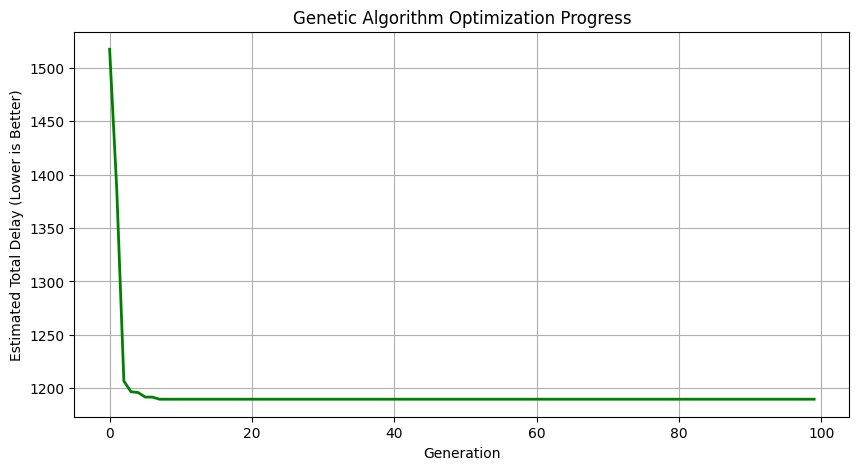

In [ ]:
# Plot the Optimization Progress
plt.figure(figsize=(10, 5))
plt.plot(best_fitness_history, color='green', linewidth=2)
plt.title('Genetic Algorithm Optimization Progress')
plt.xlabel('Generation')
plt.ylabel('Estimated Total Delay (Lower is Better)')
plt.grid(True)
plt.show()

## Advanced Idea: Multi-Objective Traffic Optimization

Real-world traffic management has competing priorities:
1. **Minimizing Overall Delay**: Keeping the throughput high.
2. **Minimizing Fuel Consumption & Emissions**: Vehicles idling or constantly decelerating/accelerating at red lights emit more CO2.
3. **Maximizing Fairness**: Preventing minor phases from being starved (waiting indefinitely while major lanes stay green).

We can design a weighted multi-objective fitness function to balance these elements or optimize them together. Let's implement this advanced traffic model.

In [ ]:
# Multi-Objective Simulation Constants
EMISSION_FACTOR = 0.25  # kg CO2 per vehicle per minute of idling
MAX_FAIR_WAIT_TIME = 90  # Seconds of maximum green-light deprivation before heavy penalty

def calculate_multi_objective_metrics(chromosome):
    """
    Calculates metrics for three main objectives: Delay, Emissions, and Inequity (Fairness).
    """
    delays = []
    emissions = []

    for arrival_rate, green_time in zip(ARRIVAL_RATES, chromosome):
        capacity = (green_time / TOTAL_CYCLE_TIME) * 60
        if capacity <= arrival_rate:
            delay = (arrival_rate - capacity) * 12 + 60
        else:
            delay = 35 * (1 - (green_time / TOTAL_CYCLE_TIME))

        # Vehicles delayed
        vehicles_delayed = delay * arrival_rate
        delays.append(vehicles_delayed)

        # Emissions are highly correlated with waiting times
        emissions.append(vehicles_delayed * EMISSION_FACTOR)

    total_delay = sum(delays)
    total_emissions = sum(emissions)

    # Fairness metric: standard deviation of green times (lower std deviation = fairer allocation)
    # We also penalize if any phase gets less than a fair threshold proportional to its traffic
    fairness_penalty = np.std(chromosome)

    return total_delay, total_emissions, fairness_penalty

def advanced_fitness_function(chromosome, w_delay=0.5, w_emissions=0.3, w_fairness=0.2):
    """
    Combines the objectives into a single normalized fitness score.
    """
    delay, emissions, unfairness = calculate_multi_objective_metrics(chromosome)

    # Normalize factors (based on typical scale values)
    norm_delay = delay / 2000.0
    norm_emissions = emissions / 500.0
    norm_unfairness = unfairness / 30.0

    total_cost = (w_delay * norm_delay) + (w_emissions * norm_emissions) + (w_fairness * norm_unfairness)
    return 1.0 / (1.0 + total_cost)

In [ ]:
# Run Advanced Evolutionary Loop
population = [create_individual() for _ in range(POPULATION_SIZE)]

delay_history = []
emission_history = []
fairness_history = []

for generation in range(GENERATIONS):
    fitness_scores = [advanced_fitness_function(ind) for ind in population]

    best_idx = np.argmax(fitness_scores)
    best_ind = population[best_idx]

    d, e, f = calculate_multi_objective_metrics(best_ind)
    delay_history.append(d)
    emission_history.append(e)
    fairness_history.append(f)

    # Selection & Reproduction
    total_fitness = sum(fitness_scores)
    probs = [fit / total_fitness for fit in fitness_scores]
    new_population = [best_ind]

    while len(new_population) < POPULATION_SIZE:
        parents = random.choices(population, weights=probs, k=2)
        child = crossover(parents[0], parents[1])
        child = mutate(child)
        new_population.append(child)

    population = new_population

# Best schedule extraction
final_fitness = [advanced_fitness_function(ind) for ind in population]
best_final_idx = np.argmax(final_fitness)
best_advanced_schedule = population[best_final_idx]

print("--- Advanced Multi-Objective Optimization Results ---")
print(f"Optimized Multi-Objective Schedule: {best_advanced_schedule}")
final_d, final_e, final_f = calculate_multi_objective_metrics(best_advanced_schedule)
print(f"Total Vehicle Delay: {final_d:.2f} vehicle-seconds")
print(f"Total Carbon Footprint: {final_e:.2f} kg CO2/min")
print(f"Unfairness Index (Lower is fairer): {final_f:.2f}")

--- Advanced Multi-Objective Optimization Results ---
Optimized Multi-Objective Schedule: [41, 31, 22, 26]
Total Vehicle Delay: 1407.88 vehicle-seconds
Total Carbon Footprint: 351.97 kg CO2/min
Unfairness Index (Lower is fairer): 7.11


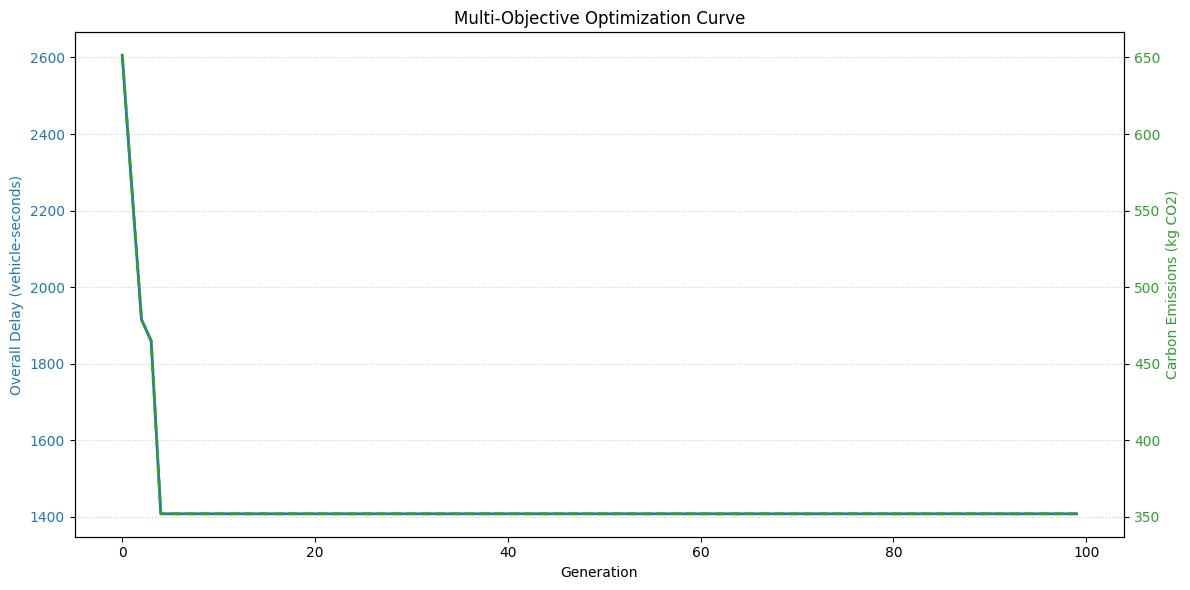

In [ ]:
# Plot Multi-Objective Metrics Trade-off Over Generations
fig, ax1 = plt.subplots(figsize=(12, 6))

color = 'tab:blue'
ax1.set_xlabel('Generation')
ax1.set_ylabel('Overall Delay (vehicle-seconds)', color=color)
ax1.plot(delay_history, color=color, label='Delay', linewidth=2)
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()
color = 'tab:green'
ax2.set_ylabel('Carbon Emissions (kg CO2)', color=color)
ax2.plot(emission_history, color=color, linestyle='--', label='Emissions', linewidth=2)
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Multi-Objective Optimization Curve')
fig.tight_layout()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()